# Soil-enabled precipitation threshold sensitivity: +1.2°C versus +0.7°C

PPSA, TRAM, and HEEN, with `hrrrak_lapserate` and `met_hrrrak_lapserate`. The control is the existing **soil** experiment with a 274.35 K (+1.2°C) air-temperature threshold. The new **soil_thresh07** experiment uses `PRECSPLITTING`, `TYPE = THRESH`, and `SNOW = 273.85 K` (+0.7°C). Soil remains enabled, with the same profiles, forcing files, snow/soil physics, filters, and output frequency. Only the precipitation cutoff and output experiment label change in effect.

Lowering the threshold changes precipitation near freezing from snow to rain. This is an air-temperature threshold sensitivity experiment. Existing controls and source inputs are preserved, with checksums recorded in each model site's `soil_thresh07_runs.json`.

The comparison uses **WY2023, WY2024, and WY2025 for PPSA/TRAM**, and **WY2020, WY2021, and WY2022 for HEEN**, for both forcing variants. Earlier PPSA/TRAM simulations are retained on disk but excluded from these plots and statistics. At each site, all four curves use the same available comparison window. The existing PPSA/TRAM runs end on September 1, 2025, so WY2025 is partial; HEEN's shared window ends September 30, 2022 at 05:00. First-season initialization flags refer to the original simulation start, not the first displayed year. All comparisons use identical hourly indices; no missing values are filled with zero. Figures display inline without automatic PNG/PDF exports.

## Figure settings

Edit each simulation's `color`, `linewidth`, and `linestyle` below, then rerun the plot cells. Use `'-'` for solid or `'--'` for dashed lines. The four labels below apply throughout the comparison. Observed snow depth is black. `ANALYSIS_YEARS` limits both figures and seasonal statistics.

In [3]:
ANALYSIS_YEARS = {'ppsa': (2023,2024,2025), 'tram': (2023,2024,2025), 'heen': (2020,2021,2022)}
FORCING_LABELS = {'hrrrak_lapserate':'HRRR-AK', 'met_hrrrak_lapserate':'Met Mixed'}
SITE_TITLES = {'ppsa':'Powder Patch (PPSA)', 'tram':'Mount Roberts Tramway (TRAM)', 'heen':'Heen Latinee (HEEN)'}
SIMULATION_STYLES = {
    ('hrrrak_lapserate','soil'): {
        'label':'HRRR-AK soil +1.2C', 'color':'tab:blue', 'linewidth':2.0, 'linestyle':'-'},
    ('hrrrak_lapserate','soil_thresh07'): {
        'label':'HRRR-AK soil +0.7C', 'color':'tab:blue', 'linewidth':2.0, 'linestyle':'--'},
    ('met_hrrrak_lapserate','soil'): {
        'label':'Met Mixed soil +1.2C', 'color':'tab:green', 'linewidth':2.0, 'linestyle':'-'},
    ('met_hrrrak_lapserate','soil_thresh07'): {
        'label':'Met Mixed soil +0.7C', 'color':'tab:green', 'linewidth':2.0, 'linestyle':'--'},
}
OBSERVATION_STYLE = {'color':'black', 'linewidth':1.25, 'alpha':.8}
MATCH_Y_AXES = True


In [4]:
from pathlib import Path
import sys, importlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from IPython.display import display, Markdown
ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents]
    if (p/'sites/all_sites/_threshold_sensitivity.py').is_file()),None)
if ROOT is None: raise RuntimeError('Run from inside snow_modeling_point')
sys.path.insert(0,str(ROOT/'sites/all_sites'))
import _threshold_sensitivity as sensitivity
importlib.reload(sensitivity)
plt.rcParams.update({'font.size':12,'axes.labelsize':13,'axes.titlesize':14,
                     'legend.fontsize':11,'axes.spines.top':False,'axes.spines.right':False})
MODEL_ROOT=sensitivity.MODEL_ROOT
manifest=[row for site in sensitivity.PERIODS for row in json.loads((MODEL_ROOT/site/'soil_thresh07_runs.json').read_text())]
all_pairs,source_coverage=sensitivity.load_pairs()
# Preserve initialization flags from the actual run starts before selecting years.
first_water_years = {key:int(frame.index[0].year+(frame.index[0].month>=10)) for key,frame in all_pairs.items()}
pairs={};plot_windows={};comparison_rows=[]
for site,years in ANALYSIS_YEARS.items():
    requested_start=pd.Timestamp(min(years)-1,10,1)
    requested_end=pd.Timestamp(max(years),10,1)-pd.Timedelta(hours=1)
    frames=[all_pairs[(site,forcing)] for forcing in sensitivity.FORCINGS]
    start=max(requested_start,max(frame.index.min() for frame in frames))
    end=min(requested_end,min(frame.index.max() for frame in frames))
    if end<start: raise ValueError(f'No common comparison period for {site}')
    plot_windows[site]=(start,end)
    for forcing in sensitivity.FORCINGS:
        frame=all_pairs[(site,forcing)].loc[start:end]
        water_year=frame.index.year+(frame.index.month>=10).astype(int)
        pairs[(site,forcing)]=frame.loc[np.isin(water_year,years)].copy()
        comparison_rows.append(dict(site=site,forcing=forcing,water_years=', '.join(map(str,years)),
            start_UTC=start,end_UTC=end,hours=len(pairs[(site,forcing)])))
metrics,observations=sensitivity.seasonal_summary(pairs,first_water_years=first_water_years)
comparison_coverage=pd.DataFrame(comparison_rows)
coverage_display=comparison_coverage.assign(forcing=comparison_coverage.forcing.map(FORCING_LABELS))
display(coverage_display.style.format({'start_UTC':lambda t:t.strftime('%d %b %Y %H:%M'),
    'end_UTC':lambda t:t.strftime('%d %b %Y %H:%M')}).hide(axis='index'))


site,forcing,water_years,start_UTC,end_UTC,hours
ppsa,HRRR-AK,"2023, 2024, 2025",01 Oct 2022 00:00,01 Sep 2025 00:00,25585
ppsa,Met Mixed,"2023, 2024, 2025",01 Oct 2022 00:00,01 Sep 2025 00:00,25585
tram,HRRR-AK,"2023, 2024, 2025",01 Oct 2022 06:00,01 Sep 2025 00:00,25579
tram,Met Mixed,"2023, 2024, 2025",01 Oct 2022 06:00,01 Sep 2025 00:00,25579
heen,HRRR-AK,"2020, 2021, 2022",01 Oct 2019 06:00,30 Sep 2022 05:00,26280
heen,Met Mixed,"2020, 2021, 2022",01 Oct 2019 06:00,30 Sep 2022 05:00,26280


## Main results: soil-enabled +1.2C and +0.7C thresholds

One panel per site, matching the step-5 main-results layout. All four hourly simulation curves and the observations share each site's three-year comparison window. PPSA and TRAM show WY2023–WY2025; HEEN shows WY2020–WY2022. No earlier years enter this figure or the statistics below. The partial final-year coverage is retained and reported above.

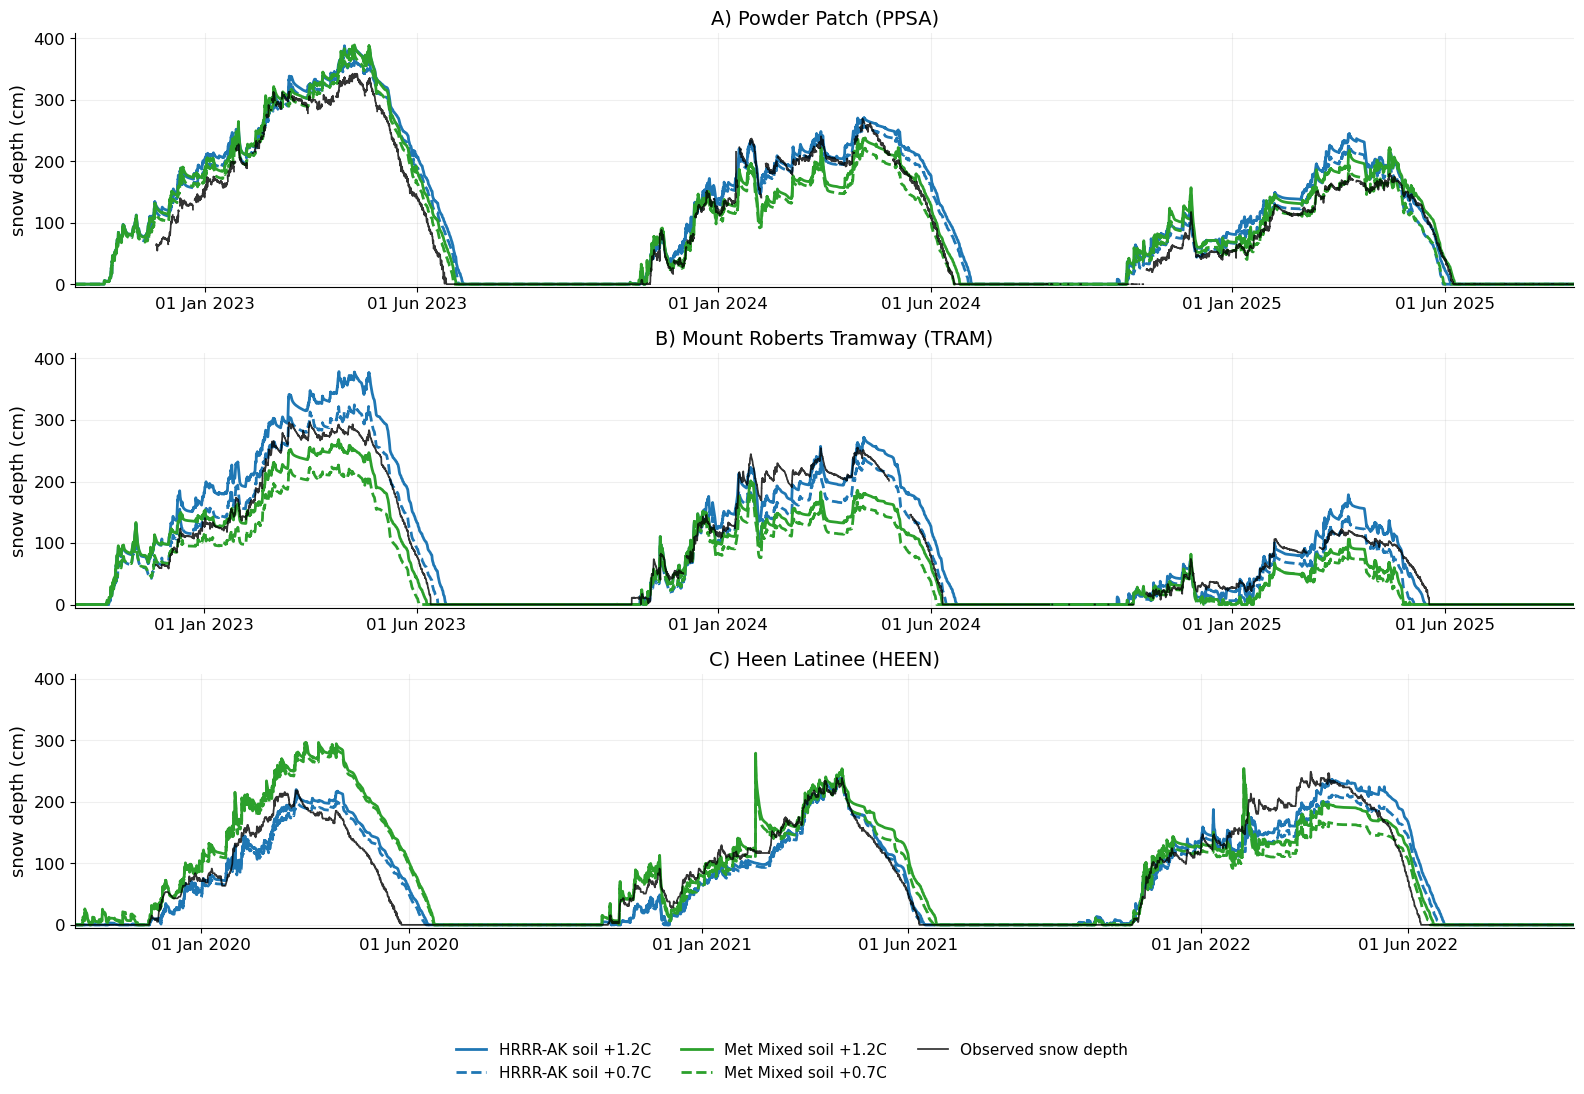

In [6]:
fig,axes=plt.subplots(3,1,figsize=(16,11),sharey=MATCH_Y_AXES)
for letter,(site,years),ax in zip('ABC',ANALYSIS_YEARS.items(),axes):
    start,end=plot_windows[site]
    for (forcing,experiment),style in SIMULATION_STYLES.items():
        frame=pairs[(site,forcing)]
        ax.plot(frame.index,frame[f'HS_cm_{experiment}'],**style)
    obs=observations[site].loc[start:end]
    ax.plot(obs.index,obs,**OBSERVATION_STYLE,label='Observed snow depth',zorder=5)
    ax.set(title=f'{letter}) {SITE_TITLES[site]}',ylabel='snow depth (cm)',xlabel='',xlim=(start,end))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1,6],bymonthday=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b %Y'))
    ax.tick_params(axis='y',labelleft=True)
    ax.grid(alpha=.2)
    ax.set_ylim(bottom=-5)
handles=[Line2D([],[],**style) for style in SIMULATION_STYLES.values()]
handles.append(Line2D([],[],**OBSERVATION_STYLE,label='Observed snow depth'))
fig.tight_layout(rect=(0,.11,1,1))
fig.legend(handles=handles,loc='lower center',ncol=3,frameon=False)
plt.show()


## Threshold response: depth and reported snowfall

All differences are **soil_thresh07 − soil**. Daily mean depth differences show the timing and direction of the response. The second column shows the cumulative difference in model-reported solid precipitation. Hourly `MS_Snow` and `MS_Rain` rates (kg m⁻² h⁻¹) are integrated over one-hour records to mm; these are model-reported fluxes, not a separately generated forcing product. The original total-precipitation forcing files are unchanged. Curves are restricted to the selected three-year windows, and cumulative changes restart at the beginning of those windows.

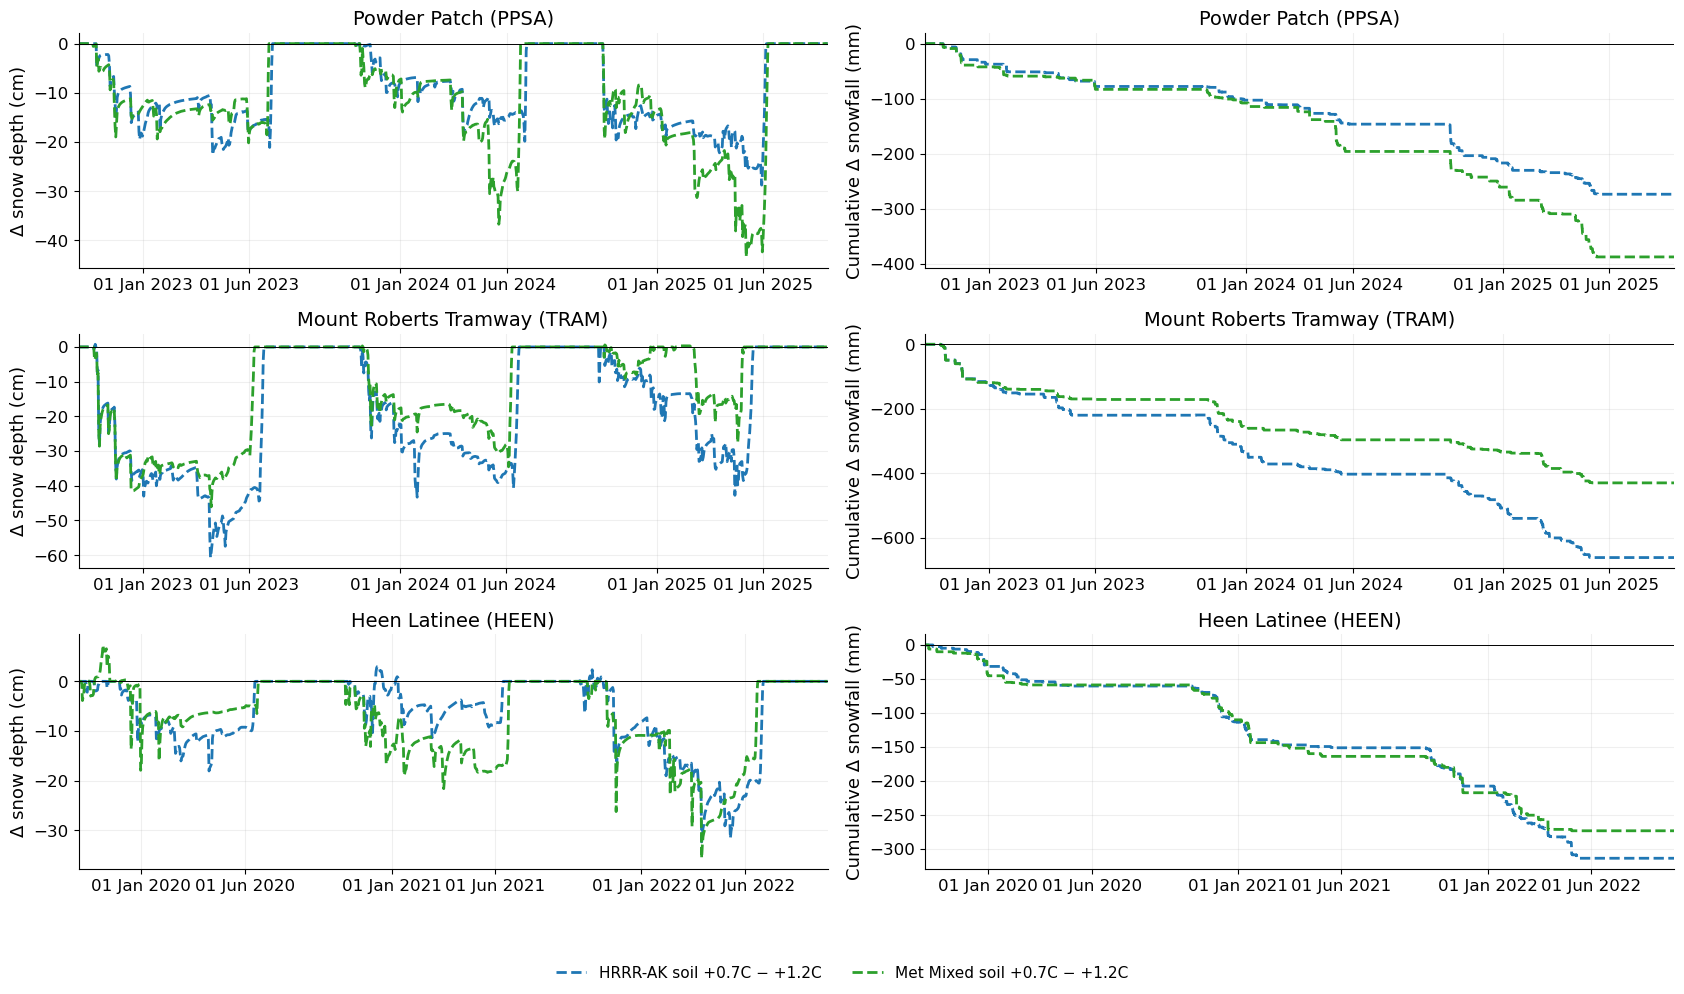

In [8]:
fig,axes=plt.subplots(3,2,figsize=(17,10))
for i,site in enumerate(ANALYSIS_YEARS):
    for forcing in sensitivity.FORCINGS:
        frame=pairs[(site,forcing)]
        # Delta lines inherit the editable +0.7C style for each forcing dataset.
        style=dict(SIMULATION_STYLES[(forcing,'soil_thresh07')])
        style['label']=style['label']+' − +1.2C'
        delta=frame.delta_HS_cm.resample('D').mean()
        axes[i,0].plot(delta.index,delta,**style)
        axes[i,1].plot(frame.index,frame.delta_snowfall_mm.cumsum(),**style)
    axes[i,0].set(title=SITE_TITLES[site],ylabel='Δ snow depth (cm)')
    axes[i,1].set(title=SITE_TITLES[site],ylabel='Cumulative Δ snowfall (mm)')
    for ax in axes[i]:
        ax.axhline(0,color='black',lw=.7);ax.grid(alpha=.2)
        ax.set_xlim(plot_windows[site])
        ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1,6],bymonthday=1))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b %Y'))
fig.tight_layout(rect=(0,.08,1,1))
handles=[Line2D([],[],**{**SIMULATION_STYLES[(f,'soil_thresh07')],
    'label':SIMULATION_STYLES[(f,'soil_thresh07')]['label']+' − +1.2C'}) for f in sensitivity.FORCINGS]
fig.legend(handles=handles,loc='lower center',ncol=2,frameon=False)
plt.show()


## Seasonal statistics

The melt-out calculation reuses the established step-5 rule: modeled snow depth ≤1 cm and SWE ≤1 mm for seven consecutive days, at least 18 valid hours/day, sufficient March–August coverage, and a substantial seasonal snowpack. The status columns distinguish a confirmed date from insufficient coverage or an unconfirmed disappearance. Positive melt shifts mean later disappearance at +0.7°C; negative shifts mean earlier disappearance.

Observation MAE/RMSE/bias use only the common valid hourly observations. Negative MAE changes mean improved modeled depth agreement. Partial water years and first seasons remain flagged and are not silently treated as complete independent seasons.

Only the three selected water years per site enter these statistics. Initialization-sensitive flags retain the original run start: PPSA/TRAM HRRR-only WY2023 is not mislabeled as an initial model season.

In [10]:
columns=['site','forcing','water_year','initialization_sensitive','complete_water_year','paired_hours','obs_hours',
    'mean_absolute_delta_HS_cm','peak_HS_soil_cm','peak_HS_soil_thresh07_cm','peak_HS_change_cm',
    'peak_SWE_change_mm','reported_snowfall_change_mm','melt_soil','melt_soil_thresh07',
    'melt_shift_days','melt_soil_status','melt_soil_thresh07_status','MAE_soil_cm','MAE_soil_thresh07_cm','MAE_change_cm',
    'RMSE_soil_cm','RMSE_soil_thresh07_cm','RMSE_change_cm']
seasonal_display=metrics[columns].round(2).copy()
seasonal_display['forcing']=seasonal_display.forcing.map(FORCING_LABELS)
for column in ['melt_soil','melt_soil_thresh07']:
    seasonal_display[column]=pd.to_datetime(seasonal_display[column]).dt.strftime('%d %b %Y').fillna('Not confirmed')
display(seasonal_display)
# A season-level summary avoids giving longer model runs extra weight.
summary=metrics.groupby(['site','forcing'],sort=False).agg(
    seasons=('water_year','count'),obs_hours=('obs_hours','sum'),
    mean_absolute_depth_change_cm=('mean_absolute_delta_HS_cm','mean'),
    mean_peak_depth_change_cm=('peak_HS_change_cm','mean'),
    mean_reported_snowfall_change_mm=('reported_snowfall_change_mm','mean'),
    mean_melt_shift_days=('melt_shift_days','mean'),confirmed_melt_pairs=('melt_shift_days','count'),
    mean_MAE_change_cm=('MAE_change_cm','mean'),
    mean_RMSE_change_cm=('RMSE_change_cm','mean'))
display(summary.rename(index=FORCING_LABELS,level='forcing').round(2))


,site,forcing,water_year,initialization_sensitive,complete_water_year,paired_hours,obs_hours,mean_absolute_delta_HS_cm,peak_HS_soil_cm,peak_HS_soil_thresh07_cm,...,melt_soil_thresh07,melt_shift_days,melt_soil_status,melt_soil_thresh07_status,MAE_soil_cm,MAE_soil_thresh07_cm,MAE_change_cm,RMSE_soil_cm,RMSE_soil_thresh07_cm,RMSE_change_cm
0,ppsa,HRRR-AK,2023,False,True,8760,5132,8.99,387.68,367.96,...,01 Jul 2023,-3,confirmed,confirmed,38.76,27.03,-11.73,45.29,32.98,-12.31
1,ppsa,HRRR-AK,2024,False,True,8784,6830,6.29,270.57,257.62,...,28 Jun 2024,-2,confirmed,confirmed,18.06,13.39,-4.68,27.91,20.97,-6.94
2,ppsa,HRRR-AK,2025,False,False,8041,7234,12.17,245.15,224.45,...,31 May 2025,-6,confirmed,confirmed,21.87,14.65,-7.22,29.70,20.39,-9.31
3,ppsa,Met Mixed,2023,False,True,8760,5132,8.80,388.99,374.98,...,28 Jun 2023,-1,confirmed,confirmed,30.53,19.64,-10.89,35.35,23.94,-11.40
4,ppsa,Met Mixed,2024,False,True,8784,6830,8.36,237.61,221.07,...,18 Jun 2024,-4,confirmed,confirmed,15.19,18.92,3.73,22.53,27.90,5.38
5,ppsa,Met Mixed,2025,False,False,8041,7234,15.10,222.04,195.45,...,01 Jun 2025,-8,confirmed,confirmed,16.27,9.04,-7.24,21.62,14.74,-6.88
6,tram,HRRR-AK,2023,False,False,8754,7373,24.59,378.67,324.65,...,17 Jun 2023,-5,confirmed,confirmed,37.57,10.73,-26.83,47.56,15.30,-32.25
7,tram,HRRR-AK,2024,False,True,8784,7342,16.41,271.80,240.01,...,12 Jun 2024,-7,confirmed,confirmed,14.20,16.75,2.55,20.75,26.32,5.57
8,tram,HRRR-AK,2025,False,False,8041,7151,11.84,178.48,145.79,...,11 May 2025,-8,confirmed,confirmed,10.64,11.25,0.61,16.48,17.02,0.54
9,tram,Met Mixed,2023,True,False,8754,7373,19.94,267.95,226.78,...,03 Jun 2023,-6,confirmed,confirmed,18.51,33.13,14.62,25.43,46.15,20.73


seasons  obs_hours  mean_absolute_depth_change_cm  \
site forcing                                                        
ppsa HRRR-AK          3      19196                           9.15   
     Met Mixed        3      19196                          10.76   
tram HRRR-AK          3      21866                          17.61   
     Met Mixed        3      21866                          11.68   
heen HRRR-AK          3      23458                           6.26   
     Met Mixed        3      23458                           7.41   

                mean_peak_depth_change_cm  mean_reported_snowfall_change_mm  \
site forcing                                                                  
ppsa HRRR-AK                       -17.79                            -91.27   
     Met Mixed                     -19.05                           -129.26   
tram HRRR-AK                       -39.50                           -220.37   
     Met Mixed                     -25.93                           -143.19   
heen HRRR-AK                       -13.54                           -104.54   
     Met Mixed                      -9.65                            -91.07   

                mean_melt_shift_days  confirmed_melt_pairs  \
site forcing                                                 
ppsa HRRR-AK                   -3.67                     3   
     Met Mixed                 -4.33                     3   
tram HRRR-AK                   -6.67                     3   
     Met Mixed                 -3.33                     3   
heen HRRR-AK                   -2.00                     3   
     Met Mixed                 -1.33                     3   

                mean_MAE_change_cm  mean_RMSE_change_cm  
site forcing                                             
ppsa HRRR-AK                 -7.87                -9.52  
     Met Mixed               -4.80                -4.30  
tram HRRR-AK                 -7.89                -8.72  
     Met Mixed                9.45                12.80  
heen HRRR-AK                 -0.09                -0.28  
     Met Mixed               -0.07                 0.00

## Running and provenance

Each model site has `run_soil_thresh07.sh` and `soil_thresh07_runs.json`. Config filenames retain forcing, soil experiment, site, and period, for example `hrrrak_lapserate_soil_thresh07_ppsa_WY2020-WY2025.ini`; outputs use the original station stem followed by `_soil_thresh07`. The run scripts refuse to overwrite existing sensitivity outputs.

To prepare the same setup or run the six cases from the repository root with the JIF scientific environment:

```bash
python sites/all_sites/_threshold_sensitivity.py prepare
python sites/all_sites/_threshold_sensitivity.py run --workers 6
```

Model-run status JSON files verify completion, matching hourly coverage, and preservation of the forcing files, soil profiles, original configs, and original soil timeseries. This notebook only reads model files. Optional diagnostic table exports belong in the ignored `temporary/soil_thresh07/` folder; none are written automatically.

In [12]:
status=[]
for row in manifest:
    path=Path(row['output']).with_suffix('.status.json')
    status.append(json.loads(path.read_text()))
status_display=pd.DataFrame(status)
status_display['forcing']=status_display.forcing.map(FORCING_LABELS)
display(status_display[['site','forcing','returncode','finished','complete','rows',
    'inputs_preserved','control_preserved']])


,site,forcing,returncode,finished,complete,rows,inputs_preserved,control_preserved
0,ppsa,HRRR-AK,0,True,True,51883,True,True
1,ppsa,Met Mixed,0,True,True,51883,True,True
2,tram,HRRR-AK,0,True,True,51883,True,True
3,tram,Met Mixed,0,True,True,25579,True,True
4,heen,HRRR-AK,0,True,True,51883,True,True
5,heen,Met Mixed,0,True,True,26280,True,True


## Concise performance summary

Changes below are **+0.7C − +1.2C**, using only the selected three water years at each site. Negative RMSE changes mean better agreement with observed snow depth; negative melt-out shifts mean earlier disappearance. Each forcing-season contributes equally to the medians. Confirmed melt-date pairs are counted separately from seasons with observations.

In [14]:
performance_rows=[]
for site in ANALYSIS_YEARS:
    use=metrics.loc[metrics.site.eq(site)]
    error=use.dropna(subset=['RMSE_change_cm'])
    melt=use.melt_shift_days.dropna()
    performance_rows.append(dict(site=site,forcing_seasons=len(use),observed_seasons=len(error),
        improved_RMSE=int(error.RMSE_change_cm.lt(0).sum()),
        median_RMSE_change_cm=error.RMSE_change_cm.median(),
        confirmed_melt_pairs=len(melt),median_melt_shift_days=melt.median(),
        min_melt_shift_days=melt.min(),max_melt_shift_days=melt.max(),
        median_peak_depth_change_cm=use.peak_HS_change_cm.median()))
performance_summary=pd.DataFrame(performance_rows)
valid_error=metrics.dropna(subset=['RMSE_change_cm'])
lines=[f"Lowering the threshold to **+0.7C** reduced snow-depth RMSE in "
       f"**{int(valid_error.RMSE_change_cm.lt(0).sum())}/{len(valid_error)} forcing-seasons** "
       f"(overall median RMSE change **{valid_error.RMSE_change_cm.median():+.1f} cm**)."]
for r in performance_summary.itertuples():
    melt_text=(f"median melt-out shift **{r.median_melt_shift_days:+.1f} days** "
               f"(range {r.min_melt_shift_days:+.0f} to {r.max_melt_shift_days:+.0f}; "
               f"{r.confirmed_melt_pairs} confirmed pairs)") if r.confirmed_melt_pairs else "no confirmed melt-date pairs"
    lines.append(f"- **{r.site.upper()}:** RMSE lower in {r.improved_RMSE}/{r.observed_seasons} forcing-seasons "
                 f"(median change {r.median_RMSE_change_cm:+.1f} cm); {melt_text}; "
                 f"median peak-depth change {r.median_peak_depth_change_cm:+.1f} cm.")
initial=int(metrics.initialization_sensitive.sum())
partial=int((~metrics.complete_water_year).sum())
lines.append(f"These summaries include {initial} initialization-sensitive and {partial} partial-water-year "
             "forcing-seasons (flags may overlap); see the seasonal table. Earlier melt or reduced depth "
             "does not by itself indicate better observation agreement.")
display(Markdown(lines[0]+'\n\n'+'\n'.join(lines[1:-1])+'\n\n'+lines[-1]))


Lowering the threshold to **+0.7C** reduced snow-depth RMSE in **10/18 forcing-seasons** (overall median RMSE change **-1.2 cm**).

- **PPSA:** RMSE lower in 5/6 forcing-seasons (median change -8.1 cm); median melt-out shift **-3.5 days** (range -8 to -1; 6 confirmed pairs); median peak-depth change -18.1 cm.
- **TRAM:** RMSE lower in 1/6 forcing-seasons (median change +5.3 cm); median melt-out shift **-5.5 days** (range -8 to +0; 6 confirmed pairs); median peak-depth change -32.2 cm.
- **HEEN:** RMSE lower in 4/6 forcing-seasons (median change -1.2 cm); median melt-out shift **-2.0 days** (range -3 to +0; 6 confirmed pairs); median peak-depth change -11.1 cm.

These summaries include 3 initialization-sensitive and 10 partial-water-year forcing-seasons (flags may overlap); see the seasonal table. Earlier melt or reduced depth does not by itself indicate better observation agreement.